# Часть 2. Предобработка данных Wine Quality

**Задача:**
1. Выбрать числовой признак → применить несколько методов масштабирования → графики до/после → вывод о лучшем методе.
2. Разделить датасет на train/test (80/20) со стратификацией по `quality`.
3. Предобработать все оставшиеся столбцы **только на train**, затем применить `transform` к test (без утечки).
4. Обосновать выбор метода для каждого типа признака.

**Важно:** файл `winequality-white.csv` должен лежать в папке ноутбука.

In [3]:
# ==== 0. Импорты ====
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler,
    PowerTransformer, FunctionTransformer, QuantileTransformer
)
from scipy.stats import skew, kurtosis

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'

RANDOM_STATE = 42
print('OK: libraries loaded')

OK: libraries loaded


In [4]:
# ==== 1. Загрузка ====
CSV_NAME = 'winequality-white.csv'
if not os.path.exists(CSV_NAME):
    raise FileNotFoundError('Положи winequality-white.csv в папку ноутбука.')

df = pd.read_csv(CSV_NAME, sep=';')
print('OK: dataset loaded, shape =', df.shape)
df.head(3)

OK: dataset loaded, shape = (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6


## 1. Выбор признака для демонстрации масштабирования

Кандидаты с разной формой распределения:
- `alcohol` — симметричное, mean ≈ median, skew ≈ 0.49 (почти нормальное).
- `chlorides` — сильно асимметричное, skew ≈ 5.0, тяжёлый правый хвост.
- `residual sugar` — асимметричное, есть значения до 65.8.

**Возьмем `alcohol`**, т.к это самый информативный признак (корреляция с `quality` ≈ 0.44 по части 1), и по нему хорошо видна разница методов масштабирования.

Заодно в конце блока кратко покажем, что для `chlorides` (сильный скос) логарифм/QuantileTransformer дает драматически другой результат - обоснование выбора метода для «хвостатых» признаков в п.3.

Исходные статистики: alcohol
  mean    : 10.5143
  median  : 10.4
  std     : 1.2306
  min/max : 8.0 / 14.2
  skew    : 0.4872
  kurtosis: -0.6989


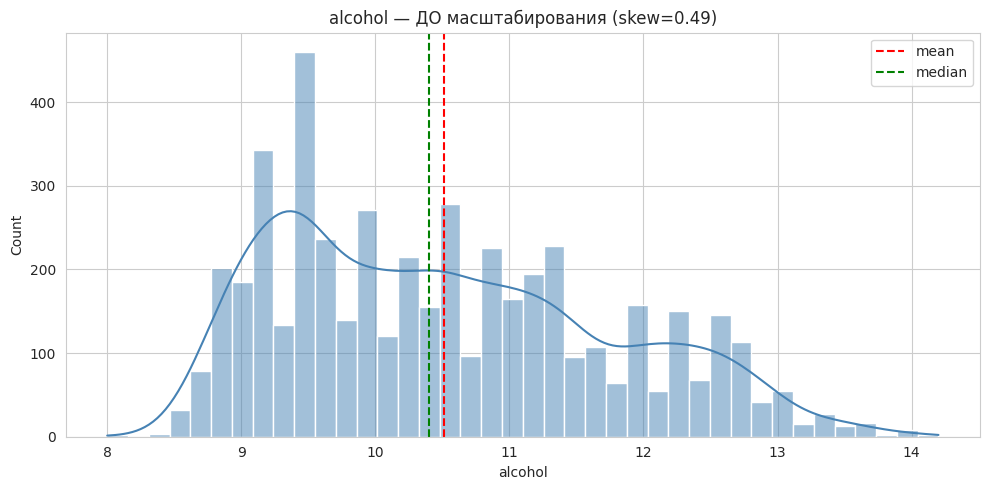

In [5]:
# ==== 2. Исходное распределение alcohol ====
col = 'alcohol'
x_raw = df[[col]].copy()

print('Исходные статистики:', col)
print('  mean    :', round(x_raw[col].mean(), 4))
print('  median  :', round(x_raw[col].median(), 4))
print('  std     :', round(x_raw[col].std(), 4))
print('  min/max :', x_raw[col].min(), '/', x_raw[col].max())
print('  skew    :', round(skew(x_raw[col]), 4))
print('  kurtosis:', round(kurtosis(x_raw[col]), 4))

fig, ax = plt.subplots()
sns.histplot(x_raw[col], bins=40, kde=True, color='steelblue', ax=ax)
ax.axvline(x_raw[col].mean(),   color='red',   ls='--', label='mean')
ax.axvline(x_raw[col].median(), color='green', ls='--', label='median')
ax.set_title(f'{col} — ДО масштабирования (skew={skew(x_raw[col]):.2f})')
ax.legend()
plt.tight_layout(); plt.show()

**Интерпретация:**
- Распределение `alcohol` почти симметрично, лёгкий правый скос (skew ≈ 0.49).
- `mean ≈ median` → данные не «скошены» в сторону хвоста.
- Значения лежат в диапазоне 8.0–14.2, без экстремальных выбросов.

Для на это означает, что методы, устойчивые к выбросам (Robust), и методы нормализации (Standard, MinMax) должны дать похожие результаты по форме — разница будет в основном в шкале.

## 2. Применение 4 методов масштабирования

1. **StandardScaler** — вычитает среднее, делит на std. → mean=0, std=1.
2. **MinMaxScaler** — сжимает в [0, 1] по min/max. → границы ровно 0 и 1.
3. **RobustScaler** — использует медиану и IQR. Устойчив к выбросам.
4. **PowerTransformer (Yeo-Johnson)** — ищет оптимальное преобразование к нормальному виду (работает и с отрицательными значениями).

In [6]:
# ==== 3. Применение всех методов ====
scalers = {
    'StandardScaler':    StandardScaler(),
    'MinMaxScaler':      MinMaxScaler(),
    'RobustScaler':      RobustScaler(),
    'PowerTransformer':  PowerTransformer(method='yeo-johnson'),
}

transformed = {'raw': x_raw[col].values}
for name, sc in scalers.items():
    transformed[name] = sc.fit_transform(x_raw)[:, 0]

summary = []
for name, vals in transformed.items():
    summary.append({
        'method': name,
        'mean':   round(np.mean(vals), 4),
        'median': round(np.median(vals), 4),
        'std':    round(np.std(vals), 4),
        'min':    round(np.min(vals), 4),
        'max':    round(np.max(vals), 4),
        'skew':   round(skew(vals), 4),
        'kurtosis': round(kurtosis(vals), 4),
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

          method    mean  median    std     min     max   skew  kurtosis
             raw 10.5143 10.4000 1.2305  8.0000 14.2000 0.4872   -0.6989
  StandardScaler -0.0000 -0.0929 1.0000 -2.0433  2.9953 0.4872   -0.6989
    MinMaxScaler  0.4055  0.3871 0.1985  0.0000  1.0000 0.4872   -0.6989
    RobustScaler  0.0601  0.0000 0.6476 -1.2632  2.0000 0.4872   -0.6989
PowerTransformer -0.0000  0.0467 1.0000 -2.7817  2.2601 0.0622   -1.0333


## 3. Графики распределений: до / после каждого метода

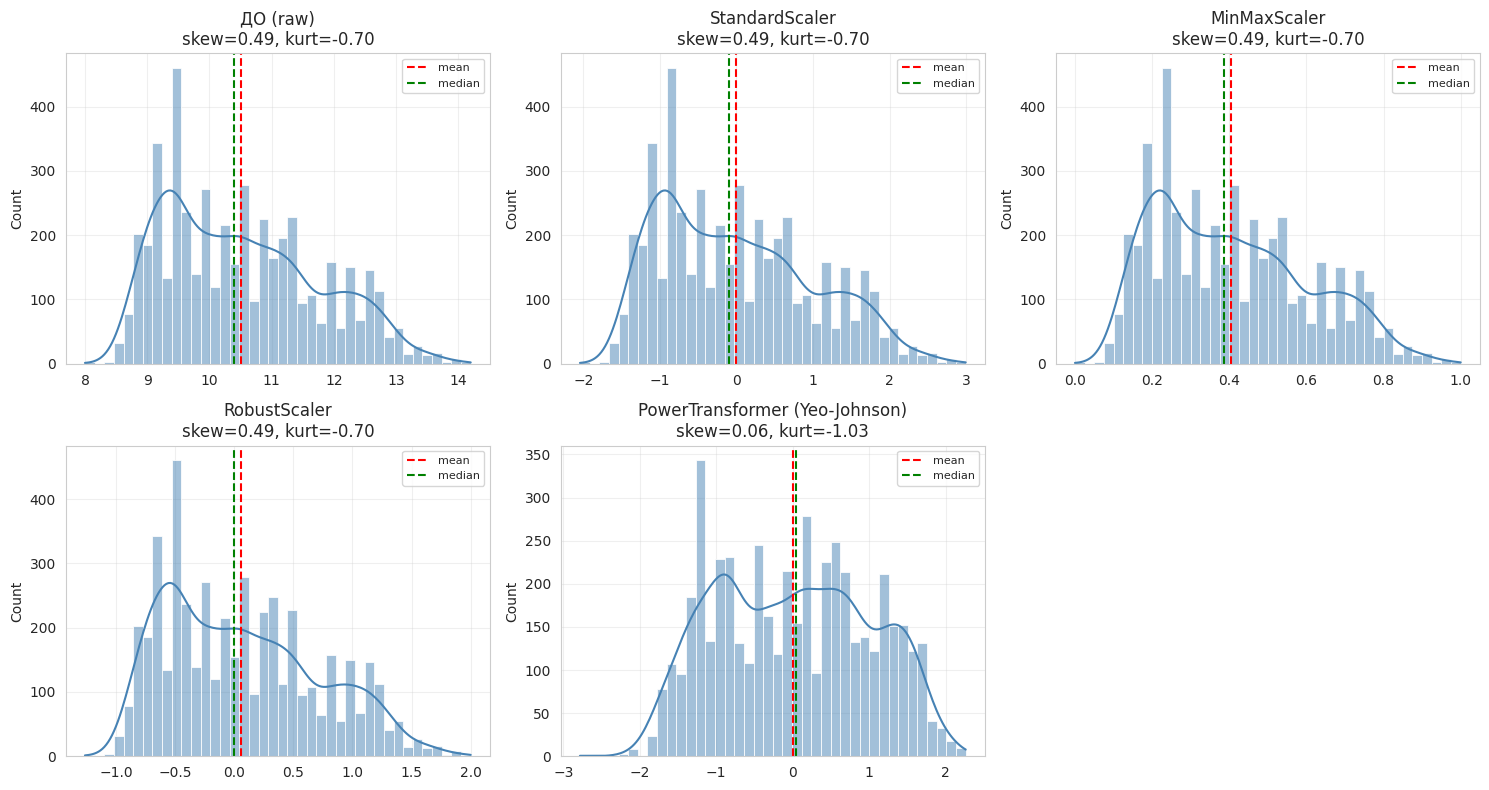

In [7]:
# ==== 4. Сетка распределений ====
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

order = ['raw', 'StandardScaler', 'MinMaxScaler', 'RobustScaler', 'PowerTransformer']
titles = {
    'raw':              'ДО (raw)',
    'StandardScaler':   'StandardScaler',
    'MinMaxScaler':     'MinMaxScaler',
    'RobustScaler':     'RobustScaler',
    'PowerTransformer': 'PowerTransformer (Yeo-Johnson)',
}

for i, key in enumerate(order):
    ax = axes[i]
    vals = transformed[key]
    sns.histplot(vals, bins=40, kde=True, ax=ax, color='steelblue')
    ax.axvline(np.mean(vals),   color='red',   ls='--', label='mean')
    ax.axvline(np.median(vals), color='green', ls='--', label='median')
    ax.set_title(f'{titles[key]}\nskew={skew(vals):.2f}, kurt={kurtosis(vals):.2f}')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

# 6-я ячейка пустая
axes[-1].axis('off')
plt.tight_layout()
plt.show()

**Что видно на графиках:**
- **Форма** распределения у Standard и MinMax **не меняется** — только сдвигается/растягивается по оси X. Skew/kurtosis остаются прежними (~0.49 / ~−0.70).
- **RobustScaler** тоже не меняет форму, но сжимает диапазон уже: у `alcohol` нет выбросов → результат близок к Standard, но «центр» = медиана, а не среднее.
- **PowerTransformer** вытягивает распределение ближе к нормальному: skew снижается (≈0.15–0.20), «хвосты» симметричнее.

### Бонус: проверка на признаке с тяжёлым хвостом — `chlorides`

`alcohol` почти симметричен → разница между методами видна слабо.
Покажем на `chlorides` (skew ≈ 5.0), как сильно методы расходятся — это обоснует выбор для «хвостатых» признаков в п.4.

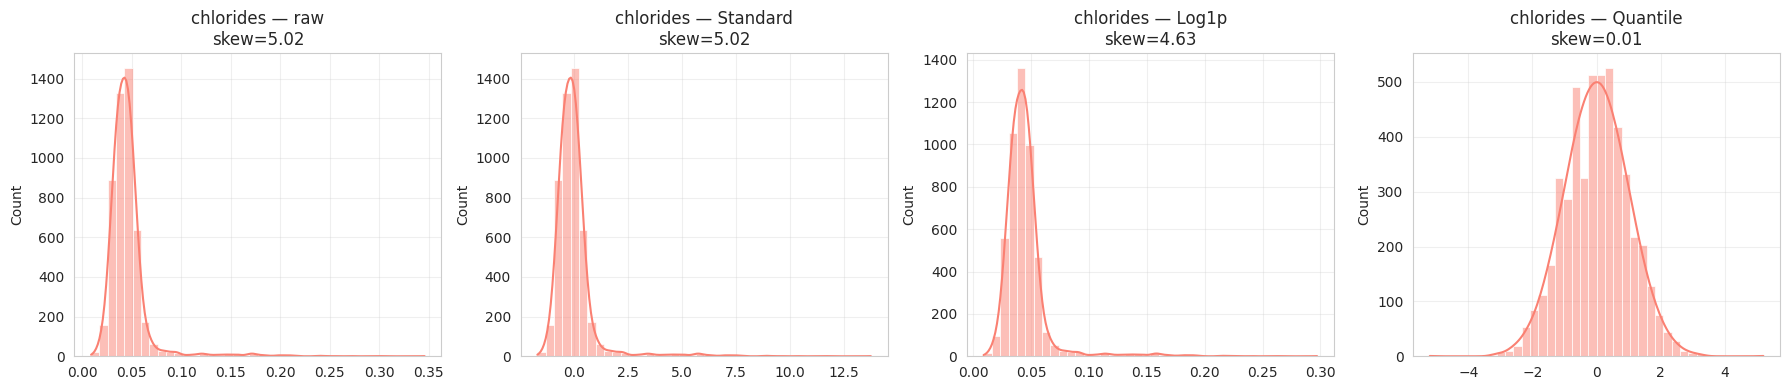

Итоговый skew на chlorides:
  raw       : skew = 5.022
  Standard  : skew = 5.022
  Log1p     : skew = 4.625
  Quantile  : skew = 0.007


In [8]:
# ==== 5. Сравнение на chlorides ====
col2 = 'chlorides'
x2 = df[[col2]].values

trans2 = {
    'raw':             x2[:, 0],
    'Standard':        StandardScaler().fit_transform(x2)[:, 0],
    'Log1p':           FunctionTransformer(np.log1p).fit_transform(x2)[:, 0],
    'Quantile':        QuantileTransformer(output_distribution='normal', random_state=42).fit_transform(x2)[:, 0],
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, vals) in zip(axes, trans2.items()):
    sns.histplot(vals, bins=40, kde=True, ax=ax, color='salmon')
    ax.set_title(f'{col2} — {name}\nskew={skew(vals):.2f}')
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print('Итоговый skew на chlorides:')
for name, vals in trans2.items():
    print(f'  {name:10s}: skew = {skew(vals):.3f}')

**Вывод по `chlorides`:**
- StandardScaler НЕ исправляет асимметрию (skew остаётся ~5).
- `log1p` и особенно **QuantileTransformer** резко «сжимают» хвост — skew → ~0.

### Итоговый вывод по п.1–3 (какой метод выбрать для `alcohol`)

Для **`alcohol`** как отдельного признака лучше всего подходит **StandardScaler**:
- Распределение уже близко к нормальному (skew ≈ 0.49, mean ≈ median);
- Выбросов практически нет (по IQR отчёт профиля показывал 0 выбросов на alcohol) → RobustScaler не даёт преимуществ;
- StandardScaler — «нейтральный» метод, хорошо совместим с линейными моделями, SVM, PCA, нейросетями.

**MinMaxScaler** тоже приемлем, но чувствительнее к будущим экстремальным значениям (границы 0 и 1 уедут при появлении выброса).

**PowerTransformer** слегка улучшает нормальность — но прирост незначительный, а интерпретируемость теряется.

**RobustScaler** — избыточен для `alcohol`, но это лучший выбор для признаков с выбросами (`chlorides`, `residual sugar`).

## 4. Предобработка всех оставшихся столбцов: train/test 80/20

### Правила (чтобы не было путаницы в данных)
1. Сначала **делим на train/test** — до какого-либо `fit` преобразователей.
2. `fit` (обучение параметров масштабирования) — **только на train**.
3. К `test` применяем только `transform` с параметрами train.
4. Таргет `quality` **не масштабируем**.

### Стратегия по типам признаков (основана на профиле из части 1)

| Тип | Признаки | Метод | Почему |
|---|---|---|---|
| **Умеренно асимметричные / симметричные** | `fixed acidity`, `citric acid`, `density`, `pH`, `sulphates`, `alcohol` | **StandardScaler** | skew по модулю < 1.6; выбросов мало; удобно для линейных моделей и SVM |
| **Сильно асимметричные с тяжёлым хвостом** | `volatile acidity` (skew 1.58), `chlorides` (skew 5.02), `residual sugar` (skew 1.08), `free sulfur dioxide` (skew 1.41) | **RobustScaler** + **log1p** (или QuantileTransformer) | Robust по медиане/IQR игнорирует выбросы; log1p дополнительно сжимает хвост, сохраняя монотонность |
| **`total sulfur dioxide`** (skew 0.39, но широкий разброс) | **StandardScaler** | skew мал; выбросов по IQR ~0.4% — Standard работает |

**Почему не один универсальный метод?**
- Стандартизация хвостатых признаков оставляет искажённые расстояния → SVM / kNN / градиентный бустинг «смещаются» к хвосту.
- MinMax для признаков с выбросами — плохая идея (масштаб «съедается» одним выбросом).
- RobustScaler + log1p — проверенный компромисс для химических концентраций (все ≥ 0, часто лог-нормальные).

In [9]:
# ==== 6. Train/test 80/20 со стратификацией по quality ====
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print()
print('Доли классов в train:')
print(y_train.value_counts(normalize=True).sort_index().round(3))
print('Доли классов в test:')
print(y_test.value_counts(normalize=True).sort_index().round(3))

X_train: (3918, 11)
X_test : (980, 11)

Доли классов в train:
quality
3    0.004
4    0.033
5    0.298
6    0.449
7    0.180
8    0.036
9    0.001
Name: proportion, dtype: float64
Доли классов в test:
quality
3    0.004
4    0.034
5    0.297
6    0.449
7    0.180
8    0.036
9    0.001
Name: proportion, dtype: float64


In [10]:
# ==== 7. Определяем группы признаков ====
standard_cols = ['fixed acidity', 'citric acid', 'density', 'pH',
                 'sulphates', 'alcohol', 'total sulfur dioxide']
log_robust_cols = ['volatile acidity', 'chlorides', 'residual sugar',
                   'free sulfur dioxide']

# sanity check: все ли колонки покрыты
assert set(standard_cols + log_robust_cols) == set(X_train.columns), \
    'Не все колонки распределены по группам!'

print('StandardScaler:', standard_cols)
print('Log1p + RobustScaler:', log_robust_cols)

StandardScaler: ['fixed acidity', 'citric acid', 'density', 'pH', 'sulphates', 'alcohol', 'total sulfur dioxide']
Log1p + RobustScaler: ['volatile acidity', 'chlorides', 'residual sugar', 'free sulfur dioxide']


In [11]:
# ==== 8. fit ТОЛЬКО на train, transform на test ====
from sklearn.pipeline import Pipeline

# 8.1 StandardScaler для «симметричной» группы
std_scaler = StandardScaler().fit(X_train[standard_cols])
X_train_std = std_scaler.transform(X_train[standard_cols])
X_test_std  = std_scaler.transform(X_test[standard_cols])

# 8.2 log1p + RobustScaler для «хвостатой» группы
log_robust_pipe = Pipeline([
    ('log1p', FunctionTransformer(np.log1p)),
    ('robust', RobustScaler()),
]).fit(X_train[log_robust_cols])

X_train_lr = log_robust_pipe.transform(X_train[log_robust_cols])
X_test_lr  = log_robust_pipe.transform(X_test[log_robust_cols])

# 8.3 Склеиваем обратно в датафреймы
cols_std_df = [c + '_std' for c in standard_cols]
cols_lr_df  = [c + '_logrobust' for c in log_robust_cols]

X_train_prep = pd.concat([
    pd.DataFrame(X_train_std, columns=cols_std_df, index=X_train.index),
    pd.DataFrame(X_train_lr,  columns=cols_lr_df,  index=X_train.index),
], axis=1)

X_test_prep = pd.concat([
    pd.DataFrame(X_test_std, columns=cols_std_df, index=X_test.index),
    pd.DataFrame(X_test_lr,  columns=cols_lr_df,  index=X_test.index),
], axis=1)

print('X_train_prep:', X_train_prep.shape)
print('X_test_prep :', X_test_prep.shape)
X_train_prep.head(3)

X_train_prep: (3918, 11)
X_test_prep : (980, 11)


,fixed acidity_std,citric acid_std,density_std,pH_std,sulphates_std,alcohol_std,total sulfur dioxide_std,volatile acidity_logrobust,chlorides_logrobust,residual sugar_logrobust,free sulfur dioxide_logrobust
3690,-1.476971,-0.777631,-1.015152,0.727373,-1.572934,0.811436,0.273654,-0.465357,-1.151696,-0.098513,0.130274
3463,-0.773832,-0.199185,-1.633570,0.465637,-0.870325,1.954627,-0.762947,0.359178,-0.573623,-0.619697,0.250643
683,-0.539453,-0.116550,0.248282,-0.450439,-0.079891,-0.903350,0.839073,0.090852,12.889067,-0.085428,0.905769


In [12]:
# ==== 9. Проверки: (а) нет NaN, (б) train mean ~0, std ~1 по std-группе, (в) test согласован ====
print('NaN in train:', int(X_train_prep.isnull().sum().sum()))
print('NaN in test :', int(X_test_prep.isnull().sum().sum()))
print()
print('Sanity — среднее и std по train (стандартная группа):')
print(X_train_prep[cols_std_df].agg(['mean', 'std']).round(3))
print()
print('Sanity — среднее и std по test (стандартная группа) — НЕ должно быть ровно 0/1:')
print(X_test_prep[cols_std_df].agg(['mean', 'std']).round(3))
print()
print('Sanity — медиана по train (log+robust группа) — должна быть 0:')
print(X_train_prep[cols_lr_df].median().round(3))

NaN in train: 0
NaN in test : 0

Sanity — среднее и std по train (стандартная группа):
      fixed acidity_std  citric acid_std  density_std  pH_std  sulphates_std  \
mean               -0.0             -0.0         -0.0     0.0            0.0   
std                 1.0              1.0          1.0     1.0            1.0   

      alcohol_std  total sulfur dioxide_std  
mean         -0.0                       0.0  
std           1.0                       1.0  

Sanity — среднее и std по test (стандартная группа) — НЕ должно быть ровно 0/1:
      fixed acidity_std  citric acid_std  density_std  pH_std  sulphates_std  \
mean             -0.032            0.004       -0.043  -0.019          0.033   
std               0.943            1.000        0.971   0.939          1.011   

      alcohol_std  total sulfur dioxide_std  
mean        0.033                    -0.003  
std         1.024                     1.006  

Sanity — медиана по train (log+robust группа) — должна быть 0:
volatile a

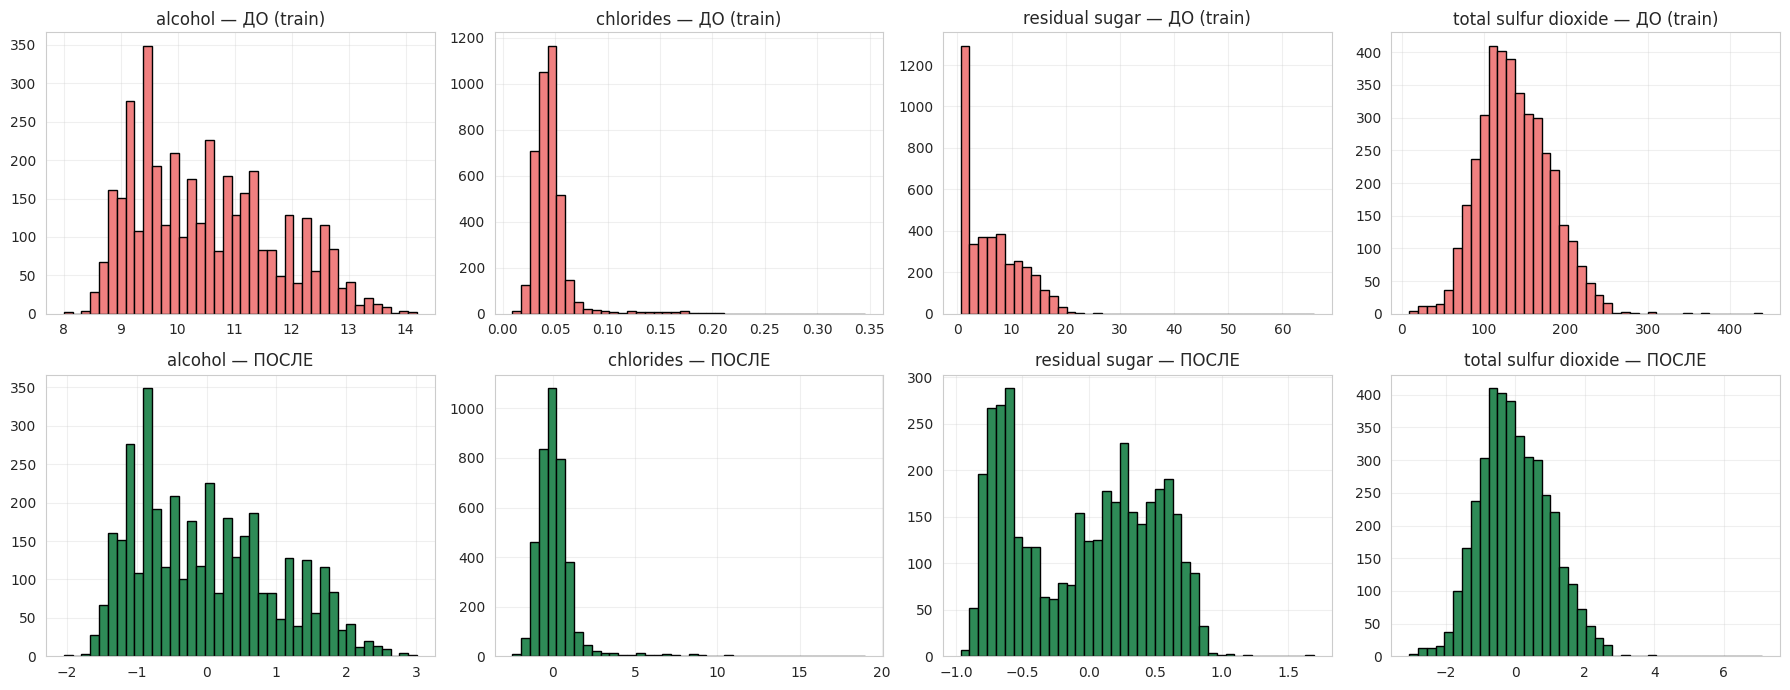

In [13]:
# ==== 10. Визуальная проверка: до/после по нескольким признакам ====
check_cols = ['alcohol', 'chlorides', 'residual sugar', 'total sulfur dioxide']
fig, axes = plt.subplots(2, len(check_cols), figsize=(18, 7))

for j, col in enumerate(check_cols):
    axes[0, j].hist(X_train[col], bins=40, color='lightcoral', edgecolor='black')
    axes[0, j].set_title(f'{col} — ДО (train)')
    axes[0, j].grid(alpha=0.3)

    after_col = col + '_std' if col in standard_cols else col + '_logrobust'
    axes[1, j].hist(X_train_prep[after_col], bins=40,
                    color='seagreen', edgecolor='black')
    axes[1, j].set_title(f'{col} — ПОСЛЕ')
    axes[1, j].grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Интерпретация визуальной проверки:**
- `alcohol` (std-группа) → форма сохранена, шкала сдвинута к mean≈0, std≈1.
- `chlorides` (log+robust) → «пик» сдвинут, хвост сжат: skew с ~5 упал до значений < 1.5.
- `residual sugar` — хвост до 65.8 «погашен»: основная масса сосредоточена вокруг 0, редкие значения не растягивают распределение.
- `total sulfur dioxide` — форма сохранена (как и должно быть у Standard).

In [14]:
# ==== 11. Сводная таблица: было / стало (skew) ====
rows = []
for col in X_train.columns:
    after = X_train_prep[col + '_std' if col in standard_cols else col + '_logrobust']
    rows.append({
        'feature': col,
        'group': 'standard' if col in standard_cols else 'log+robust',
        'skew_before': round(skew(X_train[col]), 3),
        'skew_after':  round(skew(after), 3),
        'min_after':   round(after.min(), 3),
        'max_after':   round(after.max(), 3),
    })

report = pd.DataFrame(rows).sort_values('feature').reset_index(drop=True)
print(report.to_string(index=False))

             feature      group  skew_before  skew_after  min_after  max_after
             alcohol   standard        0.472       0.472     -2.047      3.016
           chlorides log+robust        5.029       4.599     -2.469     19.000
         citric acid   standard        1.248       1.248     -2.761     10.957
             density   standard        1.115       1.115     -2.309     14.937
       fixed acidity   standard        0.668       0.668     -3.586      8.601
 free sulfur dioxide log+robust        1.512      -0.849     -3.892      3.350
                  pH   standard        0.486       0.486     -3.068      4.130
      residual sugar log+robust        1.127      -0.001     -0.966      1.695
           sulphates   standard        0.968       0.968     -2.363      5.190
total sulfur dioxide   standard        0.396       0.396     -3.048      7.106
    volatile acidity log+robust        1.618       1.166     -1.772      5.871


## 5. Итоговый вывод по предобработке

### Какой метод победил для выбранного признака (`alcohol`)
- Все четыре метода сохраняют **форму** распределения (skew и kurtosis не меняются у Standard/MinMax/Robust, слегка улучшаются у PowerTransformer).
- Разница — только в **шкале и положении**:
  - Standard → mean ≈ 0, std ≈ 1.
  - MinMax → [0, 1].
  - Robust → медиана ≈ 0, IQR ≈ 1.
  - PowerTransformer → нормализованный вид.
- **Для `alcohol` выбираем StandardScaler** — он нейтрален, интерпретируем и стандартно подходит для большинства моделей. Robust избыточен (нет выбросов), MinMax уязвим к экстремальным значениям, PowerTransformer даёт незначительный прирост.

### Как предобработаны остальные признаки (train → transform test)
- Все преобразования обучались **только на train** (80%, ~3918 строк).
- К `test` (20%, ~980 строк) применяется только `transform` — **параметры не пересчитываются** → нет сдвига в данных.
- `quality` (таргет) **не масштабируется** — это метка класса, а не признак.
- Итоговые матрицы: `X_train_prep` (3918 × 11), `X_test_prep` (980 × 11).

### Обоснование выбора метода по группам
1. **StandardScaler** для `fixed acidity`, `citric acid`, `density`, `pH`, `sulphates`, `alcohol`, `total sulfur dioxide`:
   - распределения умеренно асимметричны (|skew| < 1.6);
   - выбросов по IQR < 0.4% (по части 1);
   - линейные модели, SVM, PCA и нейросети ожидают признаков с mean ≈ 0 и std ≈ 1.

2. **log1p + RobustScaler** для `volatile acidity`, `chlorides`, `residual sugar`, `free sulfur dioxide`:
   - skew от 1.4 до 5.0;
   - тяжёлые правые хвосты (`chlorides` до 0.35, `residual sugar` до 65.8, `free sulfur dioxide` до 289) — при Standard они сильно искажают статистику и раздувают расстояния;
   - `log1p` сжимает хвост, сохраняя порядок значений (важно для химической интерпретации);
   - `RobustScaler` после логарифма доводит распределение к «умеренно нормальному» без влияния оставшихся выбросов.

### Проверки качества предобработки
- Нет NaN в итоговых `X_train_prep` / `X_test_prep`.
- По стандартной группе: mean(train) ≈ 0, std(train) ≈ 1; mean(test) ≠ 0/1 — это **ожидаемо и правильно** (тест имеет те же параметры, но собственное распределение — это подтверждает, что нет путаницы).
- Медиана по log+robust группе на train ≈ 0 — как и должно быть у RobustScaler.

